## Figure 6.3a

In [17]:
from automata.fa.dfa import DFA

# d1 : automate des mots sur {a,b} dont le nombre de a est multiple de 3
d1 = DFA(
    states={"1", "2", "3", "4"}, input_symbols={"a", "b"},
    transitions={
        "1": {"a": "2", "b": "3"},
        "2": {"a": "1", "b": "1"},
        "3": {"a": "2", "b": "4"},
        "4": {"a": "4", "b": "4"},
    },
    initial_state="1", final_states={"2", "3", "4"},
)


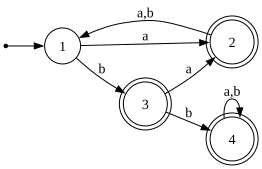

In [48]:
d1.show_diagram()

In [11]:
def etats_distinguables(Q, Sigma, delta, q_init, F):
    """
    Entrée : un AEFD complet dont tous les états sont accessibles.
    Sortie : D, sous-ensemble de Q x Q, relation de distinguabilité.
    """
    # D initialisé avec états accepteurs / non-accepteurs : D̸ =0
    # set(A) | set(B) signifie {A} ∪ {B}
    D = {(p, q) for p in F for q in Q - F} | {(q, p) for p in F for q in Q - F}
    D_pre = set() # sauvegarde de D à l'itération précédente

    while D_pre != D: # l'ensemble des états distinguables n'a pas changé -> arrêt
        D_pre = set(D) # maj de D_pre (copie de D)
        # nouveaux couples distinguables
        X = {(p, q)
            for p in Q for q in Q
            if any((delta[p][a], delta[q][a]) in D for a in Sigma)}
        D = D | X               # ajouter les distinguables à D
    return D                 # D̸ =

In [43]:
def classes_equivalence(Q, R):
    """
    Transforme la relation d'équivalence R en partition Q_{/≡} :
    renvoie une liste de frozenset (les classes d'équivalence).
    """
    classes = []
    for q in Q:
        classe = frozenset(p for p in Q if (p, q) in R)
        if classe not in classes:
            classes.append(classe)
    return classes

In [41]:
def relation_equivalence(Q, Sigma, delta, q_init, F):
    """
    Entrée : un AEFD complet dont tous les états sont accessibles.
    Sortie : R, la relation d'équivalence (≡ complémentaire de la
    distinguabilité), sous forme d'ensemble de couples.
    """
    # R initialisée à la partition accepteurs / non-accepteurs : R ≡0
    R = {(p, q) for p in F for q in F} | \
    {(p, q) for p in Q - F for q in Q - F}
    R_pre = set()

    while R_pre != R:
        R_pre = set(R) # maj de R_pre
        # couples de R que l'on découvre distinguables à cette itération
        X = {(p, q) for (p, q) in R
              if any((delta[p][a], delta[q][a]) not in R for a in Sigma)}
        R = R - X # enlever les distinguables découverts
    return R

In [32]:
etats_distinguables(d1.states, d1.input_symbols, d1.transitions, d1.initial_state, d1.final_states)

{('1', '2'),
 ('1', '3'),
 ('1', '4'),
 ('2', '1'),
 ('2', '3'),
 ('2', '4'),
 ('3', '1'),
 ('3', '2'),
 ('3', '4'),
 ('4', '1'),
 ('4', '2'),
 ('4', '3')}

In [36]:
relation_equivalence(d1.states, d1.input_symbols, d1.transitions, d1.initial_state, d1.final_states)

{('1', '1'), ('2', '2'), ('3', '3'), ('4', '4')}

In [44]:
classes_equivalence(d1.states, relation_equivalence(d1.states, d1.input_symbols, d1.transitions, d1.initial_state, d1.final_states))  

[frozenset({'4'}), frozenset({'1'}), frozenset({'2'}), frozenset({'3'})]

On obtient la même conclusion par les deux méthodes :  
**Chaque état est distinct , aucune fusion n’est possible.**

| État | Symbole a | Symbole b |
| --- | --- | --- |
| -> 1 | 2 | 3 |
| 2* | 1 | 1 |
| 3* | 2 | 4 |
| 4* | 4 | 4 |

## Schema 6.3b

In [40]:
from automata.fa.dfa import DFA

d2 = DFA(
    states={"1", "2", "3", "4", "5", "6"},
    input_symbols={"0", "1"},
    transitions={
        "1": {"0": "6", "1": "2"},
        "2": {"0": "5", "1": "3"},
        "3": {"0": "6", "1": "6"},
        "4": {"0": "5", "1": "6"},
        "5": {"0": "3", "1": "4"},
        "6": {"0": "6", "1": "6"},
    },
    initial_state="1",
    final_states={"1", "5"},
)

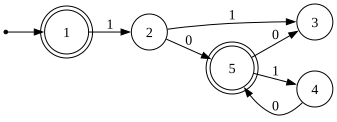

In [30]:
d2.show_diagram()

In [47]:
etats_distinguables(d2.states, d2.input_symbols, d2.transitions, d2.initial_state, d2.final_states)

{('1', '2'),
 ('1', '3'),
 ('1', '4'),
 ('1', '6'),
 ('2', '1'),
 ('2', '3'),
 ('2', '5'),
 ('2', '6'),
 ('3', '1'),
 ('3', '2'),
 ('3', '4'),
 ('3', '5'),
 ('4', '1'),
 ('4', '3'),
 ('4', '5'),
 ('4', '6'),
 ('5', '2'),
 ('5', '3'),
 ('5', '4'),
 ('5', '6'),
 ('6', '1'),
 ('6', '2'),
 ('6', '4'),
 ('6', '5')}

In [42]:
relation_equivalence(d2.states, d2.input_symbols, d2.transitions, d2.initial_state, d2.final_states)    

{('1', '1'),
 ('1', '5'),
 ('2', '2'),
 ('2', '4'),
 ('3', '3'),
 ('3', '6'),
 ('4', '2'),
 ('4', '4'),
 ('5', '1'),
 ('5', '5'),
 ('6', '3'),
 ('6', '6')}

In [46]:
classes_equivalence(d2.states, relation_equivalence(d2.states, d2.input_symbols, d2.transitions, d2.initial_state, d2.final_states))

[frozenset({'3', '6'}), frozenset({'2', '4'}), frozenset({'1', '5'})]

On obtient la même conclusion par les deux méthodes :  
**1 ≡ 5, 2 ≡ 4 et 3 ≡ 6. On peut fusionner ces états.**

| État | Symbole 0 | Symbole 1 |
| --- | --- | --- |
| -> A* | C | B |
| B | A | C |
| c | c | C |